In [1]:
from neo_ls_svm import NeoLSSVM as LSSVM
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import learning_curve, KFold

In [5]:
wkdir = r"C:/Users/agbob/OSUCLAB/ADD/FOSSE/osuc_digital_twin/"
data_dir = wkdir + "data/"

file_name = "cleaned_data.csv"

path = os.path.join(data_dir, file_name)

In [6]:
data = pd.read_csv(path, sep=",")

data["date"] = pd.to_datetime(data["date"], format="%Y-%m-%d %H:%M:%S")
data.set_index("date", inplace=True)

In [7]:
columns = [
    'temp_6cm', 'humi_6cm', 'pH_6cm',
    'temp_18cm', 'humi_18cm', 'pH_18cm',
    'temp_54cm', 'humi_54cm', 'pH_54cm',
    'temp_74cm', 'humi_74cm', 'pH_74cm'
]

df = data[columns]

In [8]:
def create_lagged_features(df, lag=10):
    X, y, dates = [], [], []
    for i in range(lag, len(df)):
        X.append(df.iloc[i-lag:i].values.flatten())
        y.append(df.iloc[i].values)
        dates.append(df.index[i])
    return np.array(X), np.array(y), np.array(dates)

In [9]:
Models = {'MultiOutputRegressor': MultiOutputRegressor, 'RegressorChain': RegressorChain}
scores = pd.DataFrame(columns=['Train_RMSE', 'Test_RMSE', 'Train_R2', 'Test_R2', 'Model'])
with_scale = [True, False]
window_size = 8

# add cross validation here

for modelName, modelB in Models.items():
    X, Y, dates = create_lagged_features(df, lag=window_size)

    X_train, X_test, y_train, y_test, dates_train, dates_test = train_test_split(
        X, Y, dates, test_size=0.2, random_state=42, shuffle=False
    )

    model = LSSVM()
    model = modelB(model)

    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    scores = pd.concat([
        scores, pd.DataFrame({
            'Train_RMSE': [train_rmse],
            'Test_RMSE': [test_rmse],
            'Train_R2': [train_r2],
            'Test_R2': [test_r2],
            'Model': [modelName]
        })
    ], ignore_index=True)

    print (f"Model: {modelName}")
    print (f"Train RMSE: {train_rmse}, Test RMSE: {test_rmse}")
    print (f"Train R2: {train_r2}, Test R2: {test_r2}")

C:\Users\agbob\AppData\Local\Temp\ipykernel_30428\2634273426.py:25: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  scores = pd.concat([


Model: MultiOutputRegressor
Train RMSE: 0.08270180846120412, Test RMSE: 2.8032941947291654
Train R2: 0.993409357340392, Test R2: -7.753139017458337
Model: RegressorChain
Train RMSE: 0.0718677473647714, Test RMSE: 2.7738606537231414
Train R2: 0.9952478602363434, Test R2: -7.787809480829202


In [ ]:
# Mean Squared Error: 0.027745578497311463
# R^2 Score: 0.8630733348173697

In [14]:
window_size = 24

X, Y, dates = create_lagged_features(df, lag=window_size)
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42 , shuffle=False)
model = LSSVM()
model = RegressorChain(model)
model.fit(X_train.reshape(X_train.shape[0], -1), y_train)
y_preds = model.predict(X_test.reshape(X_test.shape[0], -1))

Output Variable 1: RMSE = 2.8871, MAE = 2.5883


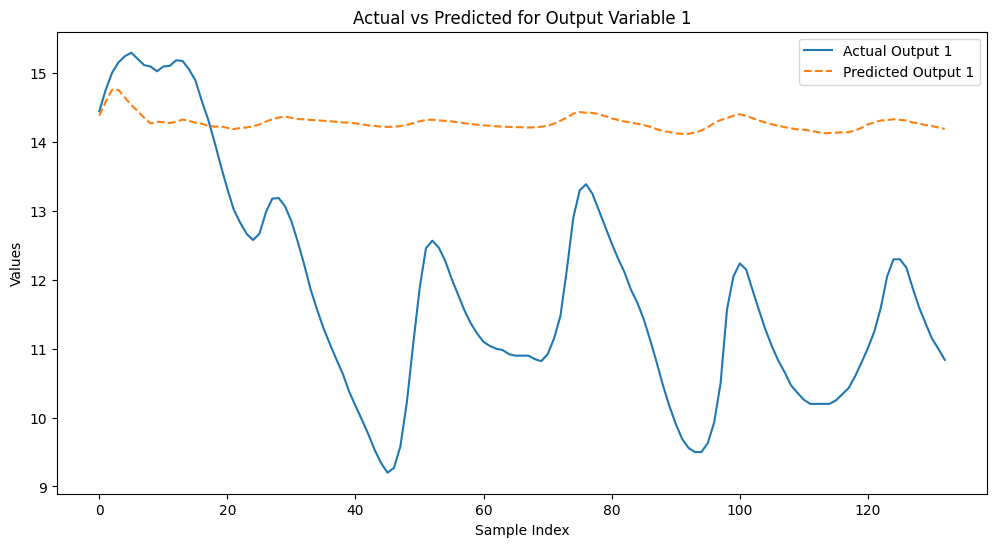

Output Variable 2: RMSE = 1.8207, MAE = 1.4598


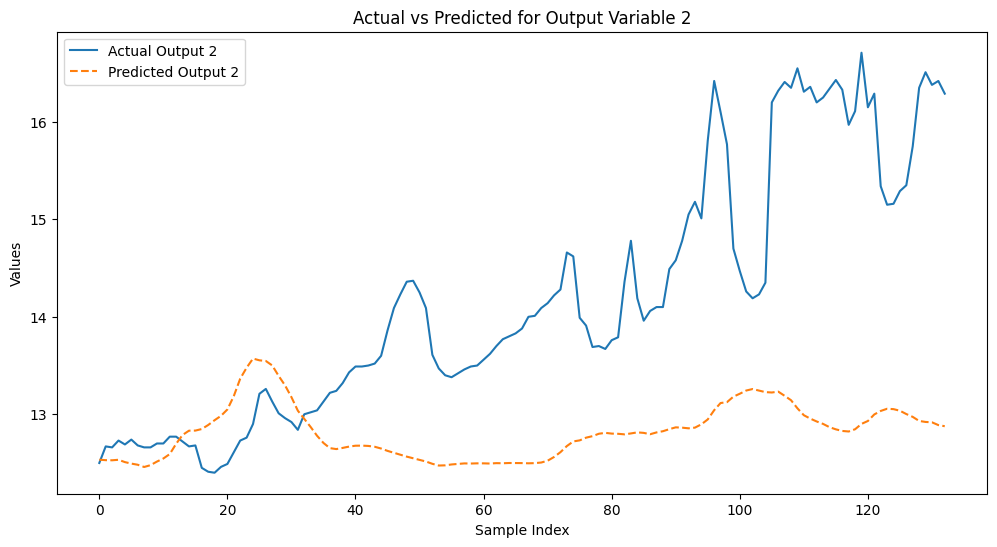

Output Variable 3: RMSE = 0.7701, MAE = 0.7041


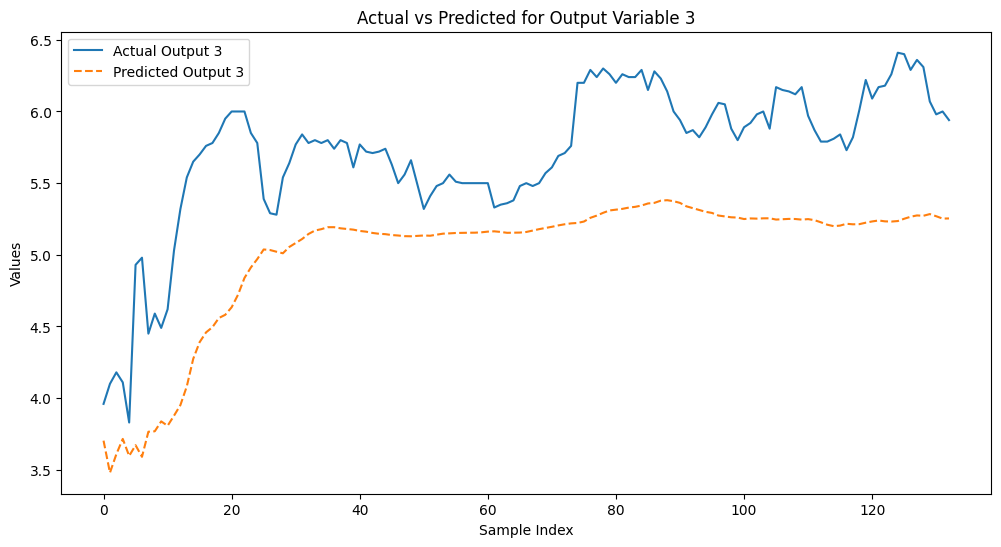

Output Variable 4: RMSE = 3.1648, MAE = 2.8548


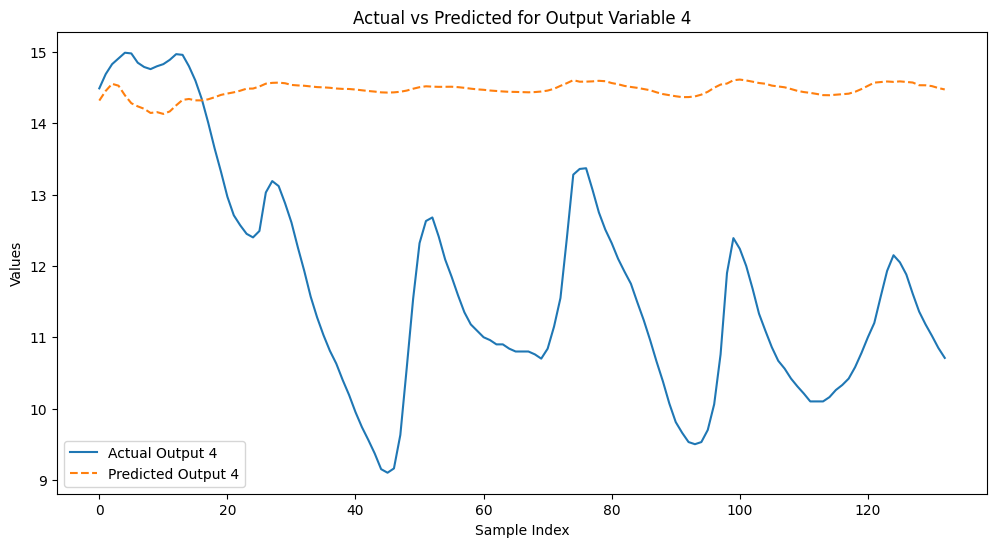

Output Variable 5: RMSE = 3.1003, MAE = 2.9582


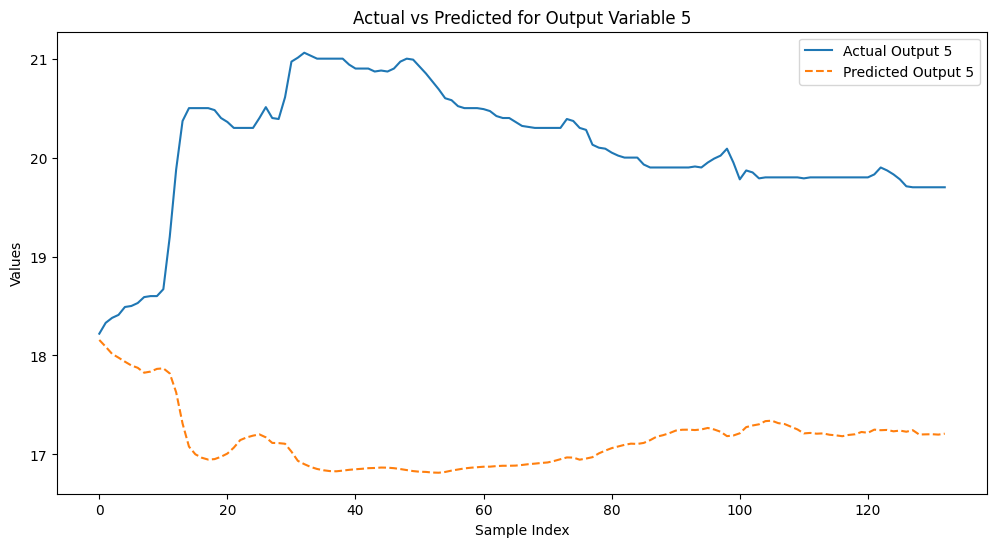

Output Variable 6: RMSE = 1.1373, MAE = 1.0436


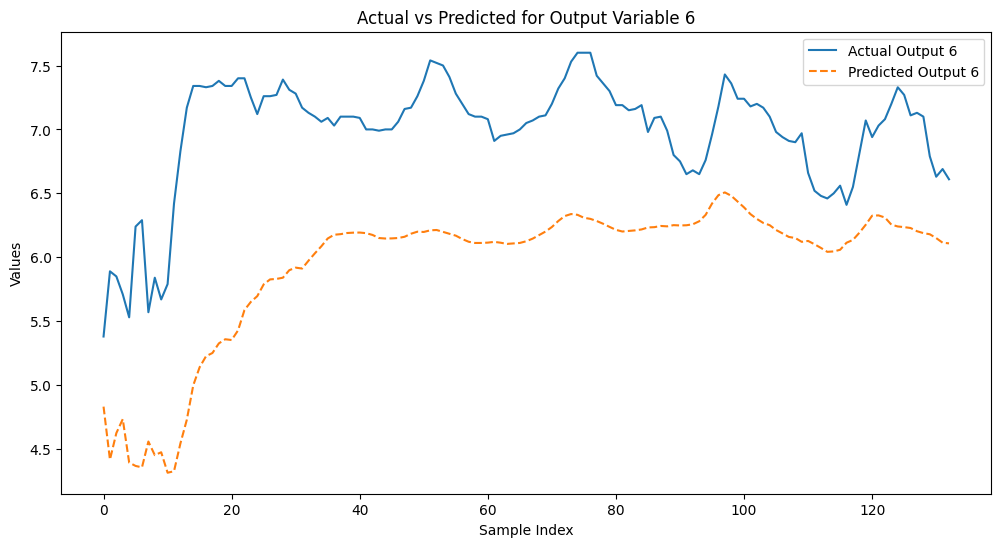

Output Variable 7: RMSE = 2.4487, MAE = 2.1968


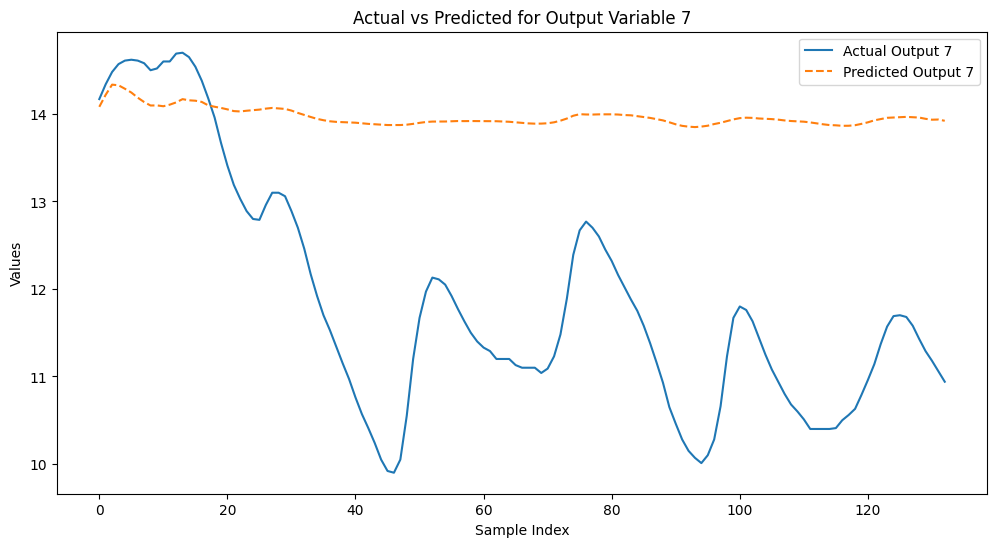

Output Variable 8: RMSE = 2.7952, MAE = 2.6304


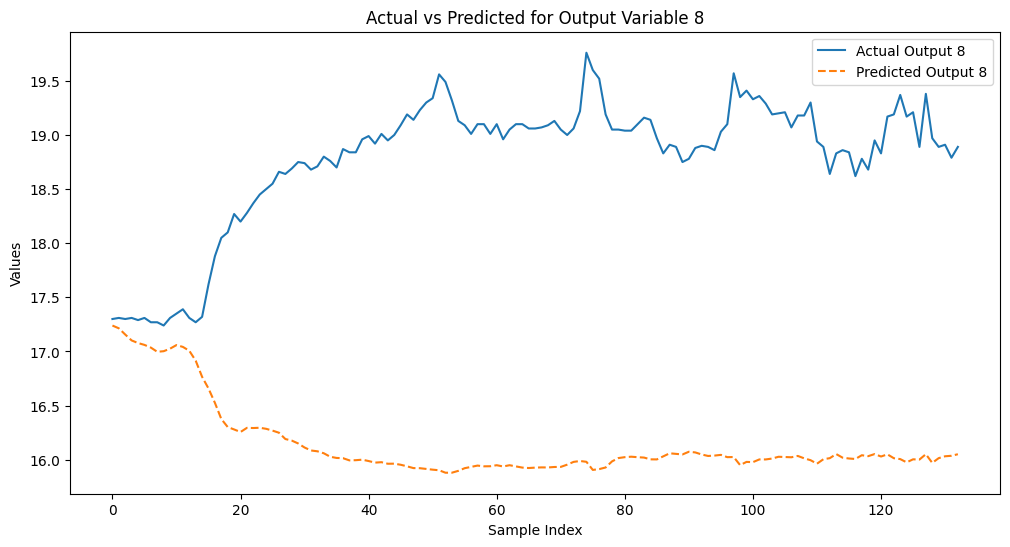

Output Variable 9: RMSE = 0.9432, MAE = 0.9079


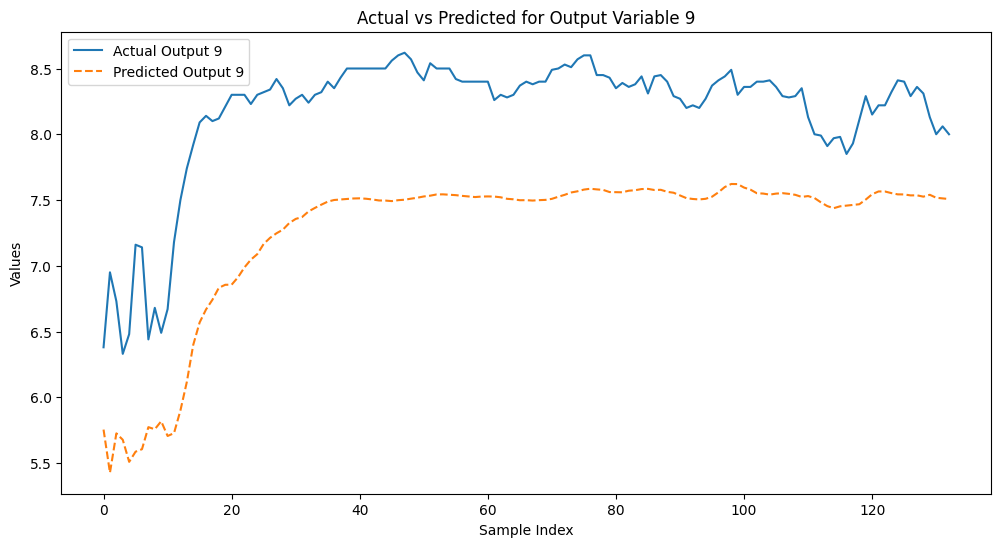

Output Variable 10: RMSE = 2.9107, MAE = 2.6174


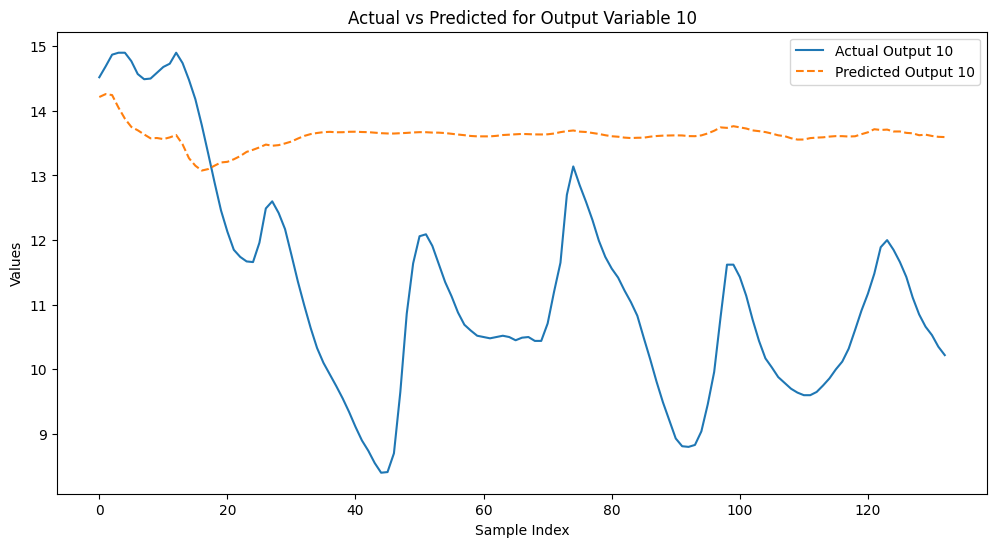

Output Variable 11: RMSE = 4.9593, MAE = 4.6844


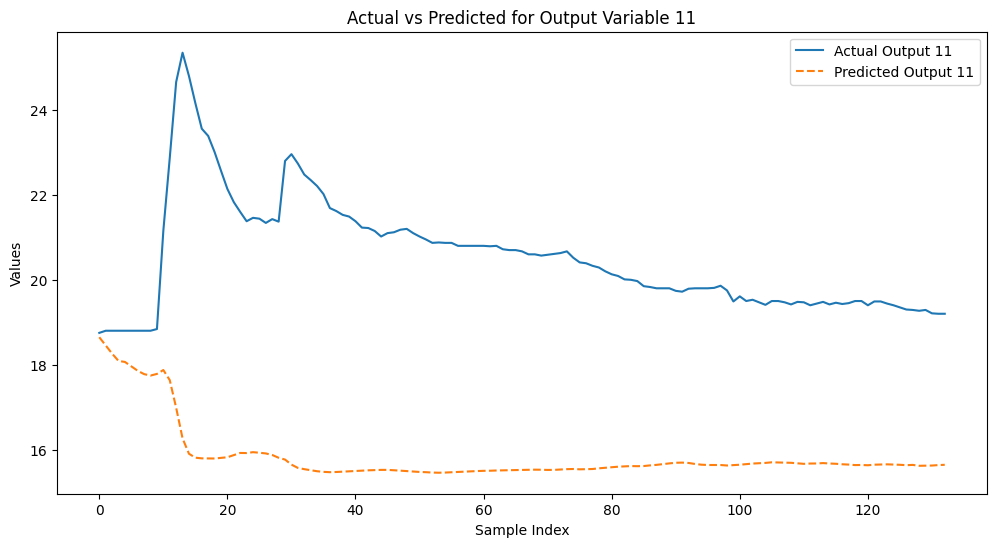

Output Variable 12: RMSE = 1.7834, MAE = 1.7198


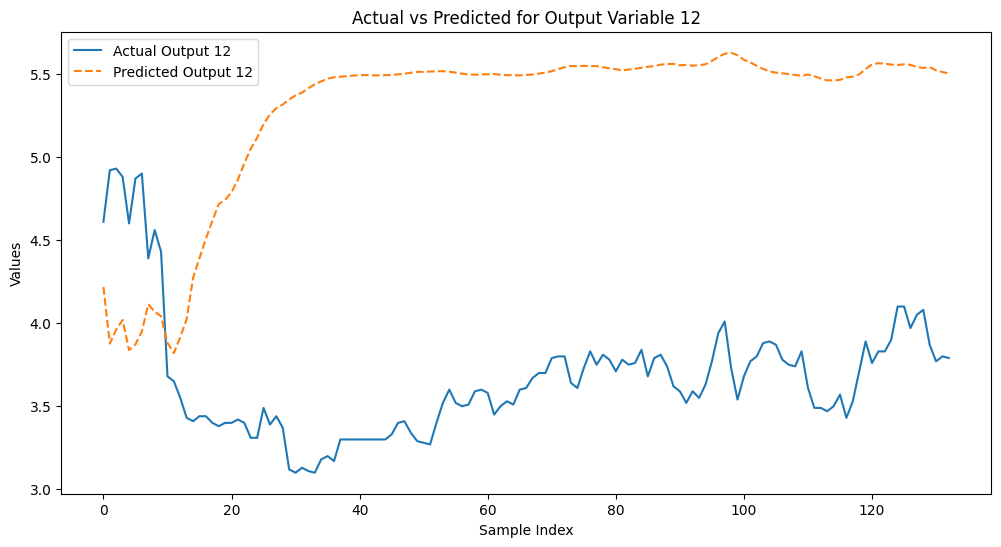

In [15]:
# Compute RMSE and MAE for each output variable
rmse = np.sqrt(mean_squared_error(y_test, y_preds, multioutput='raw_values'))
mae = np.mean(np.abs(y_test - y_preds), axis=0)  
for i in range(y_test.shape[1]):
    print(f"Output Variable {i+1}: RMSE = {rmse[i]:.4f}, MAE = {mae[i]:.4f}")
    plt.figure(figsize=(12, 6))
    plt.plot(y_test[:, i], label=f'Actual Output {i+1}')
    plt.plot(y_preds[:, i], label=f'Predicted Output {i+1}', linestyle='--')
    plt.xlabel('Sample Index')
    plt.ylabel('Values')
    plt.title(f'Actual vs Predicted for Output Variable {i+1}')
    plt.legend()
    plt.show()


In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, shuffle=False)
X_test = scaler.transform(X_test)

In [41]:
# test again
y_preds = model.predict(X_test)

In [14]:
# re construct dataframe for better visualization indexed by date
y_test_df = pd.DataFrame(y_test, columns=columns, index=X_test.index)
y_preds_df = pd.DataFrame(y_preds, columns=[f'Output_{i+1}' for i in range(y.shape[1])], index=y_test_df.index)

AttributeError: 'numpy.ndarray' object has no attribute 'index'

In [ ]:
y_test_df.head()

,Output_1,Output_2,Output_3,Output_4,Output_5,Output_6,Output_7,Output_8,Output_9,Output_10,Output_11,Output_12
0,16.60,12.98,6.76,16.80,18.05,8.48,15.80,17.35,8.93,15.87,15.53,8.13
1,16.40,12.66,6.63,16.40,17.89,8.31,15.71,17.30,8.89,15.23,15.24,7.82
2,15.99,12.42,6.65,15.88,17.76,7.98,15.47,17.24,8.99,14.50,14.96,7.42
3,15.49,12.28,6.57,15.35,17.70,7.92,15.15,17.17,9.00,13.90,14.90,7.19
4,14.94,12.07,6.50,14.89,17.67,7.82,14.82,17.11,8.94,13.35,14.84,7.09


Output Variable 1: RMSE = 0.0224, MAE = 0.0090


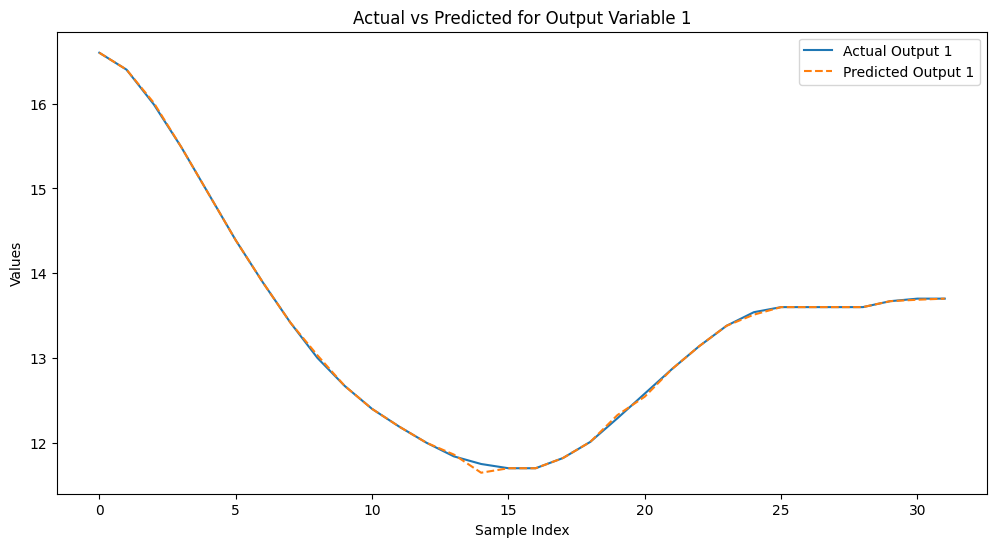

Output Variable 2: RMSE = 0.0562, MAE = 0.0414


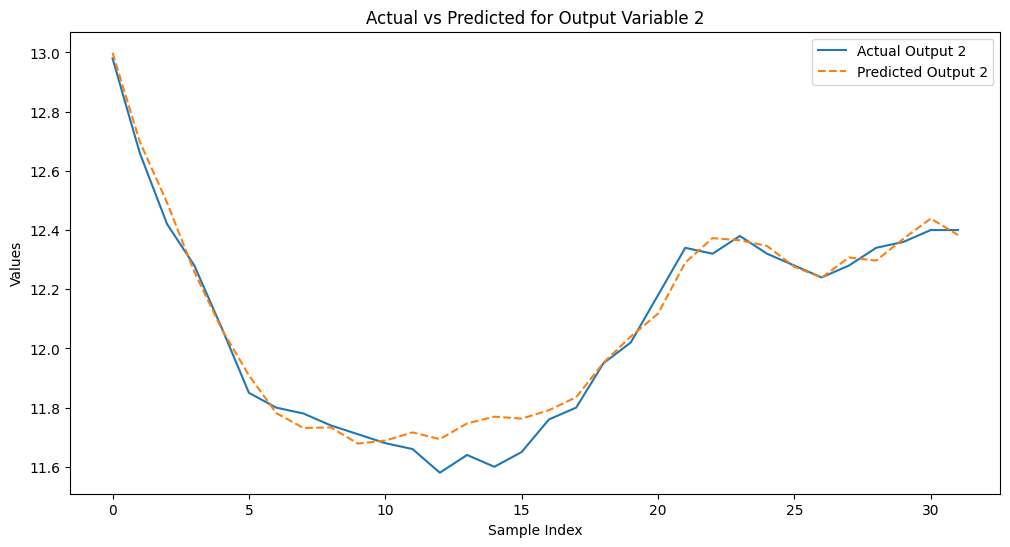

Output Variable 3: RMSE = 0.1548, MAE = 0.1150


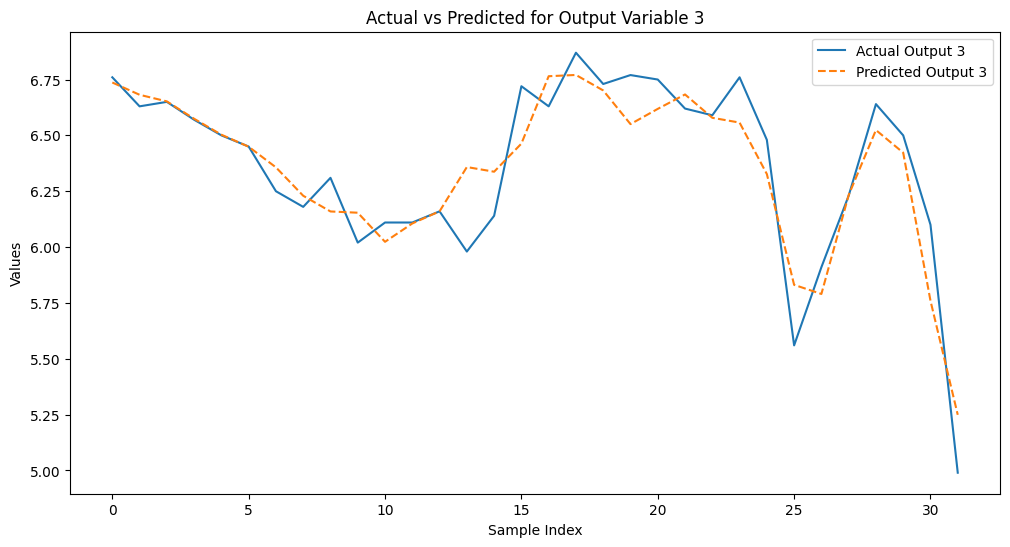

Output Variable 4: RMSE = 0.0329, MAE = 0.0138


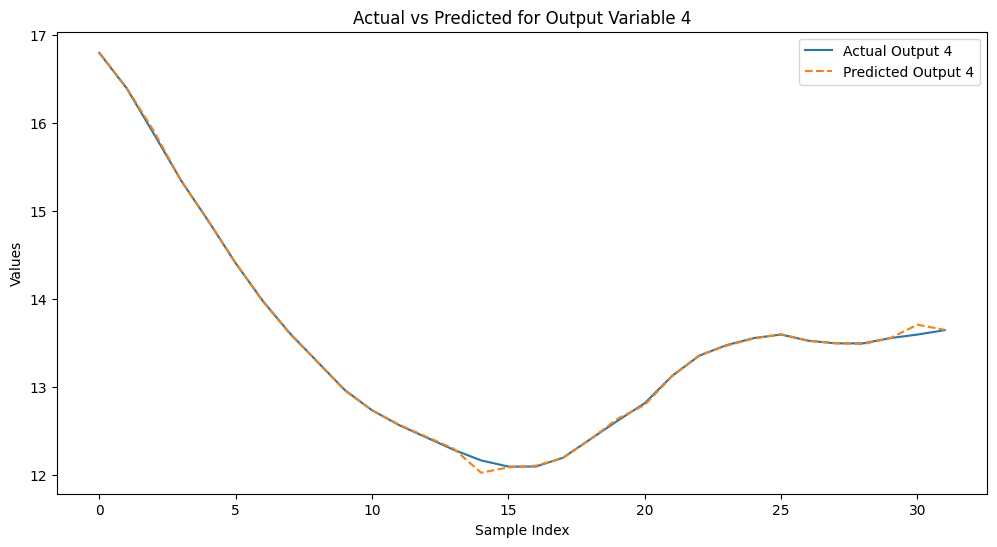

Output Variable 5: RMSE = 0.0150, MAE = 0.0086


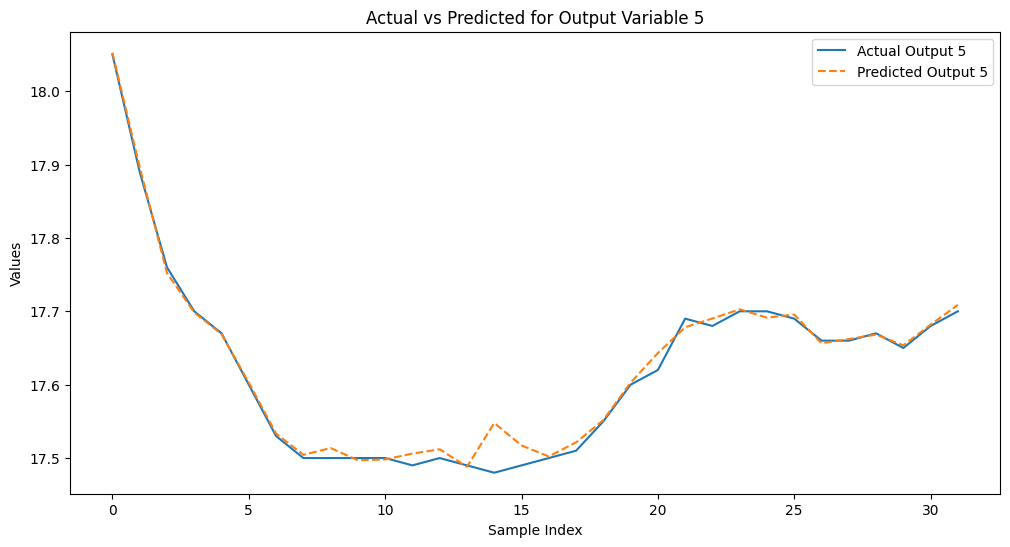

Output Variable 6: RMSE = 0.1428, MAE = 0.0766


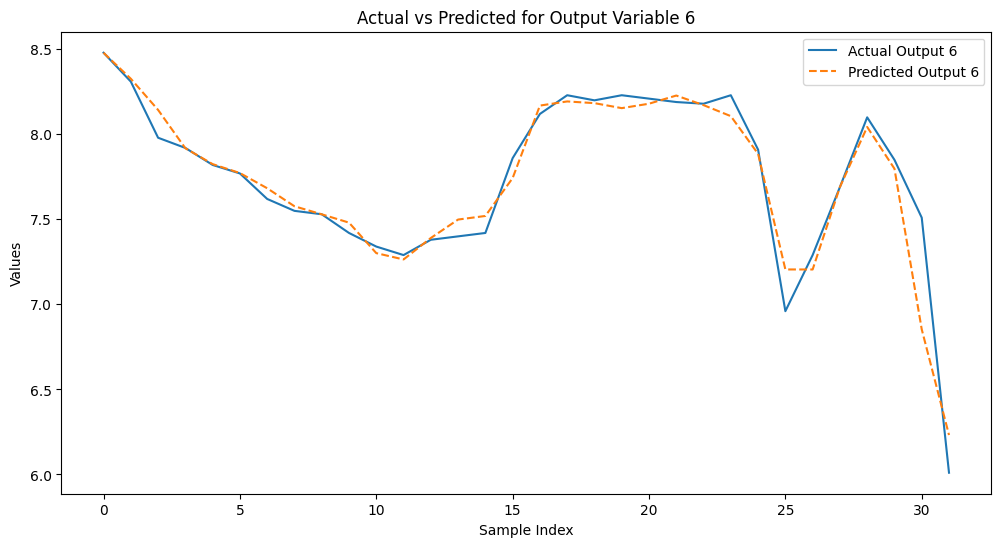

Output Variable 7: RMSE = 0.0182, MAE = 0.0090


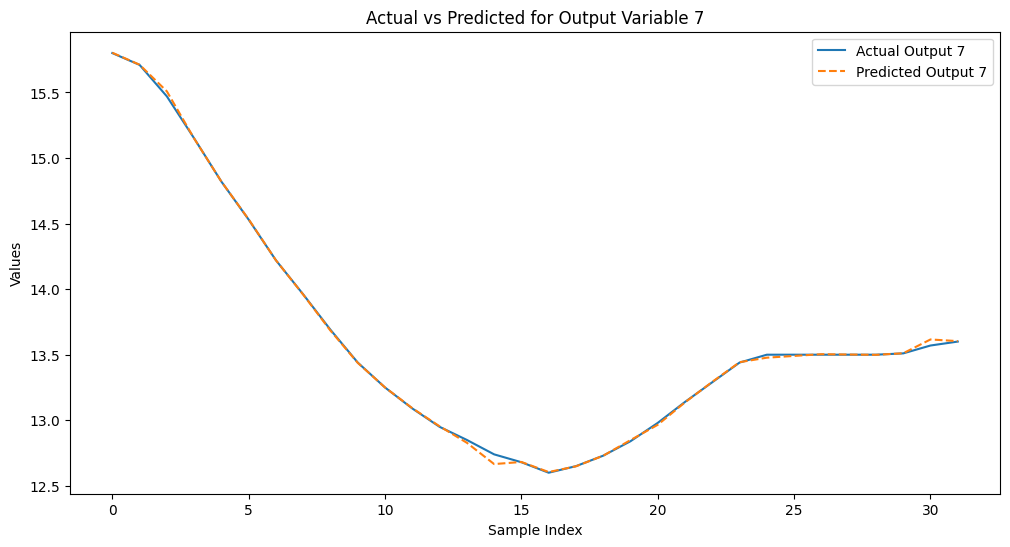

Output Variable 8: RMSE = 0.0107, MAE = 0.0070


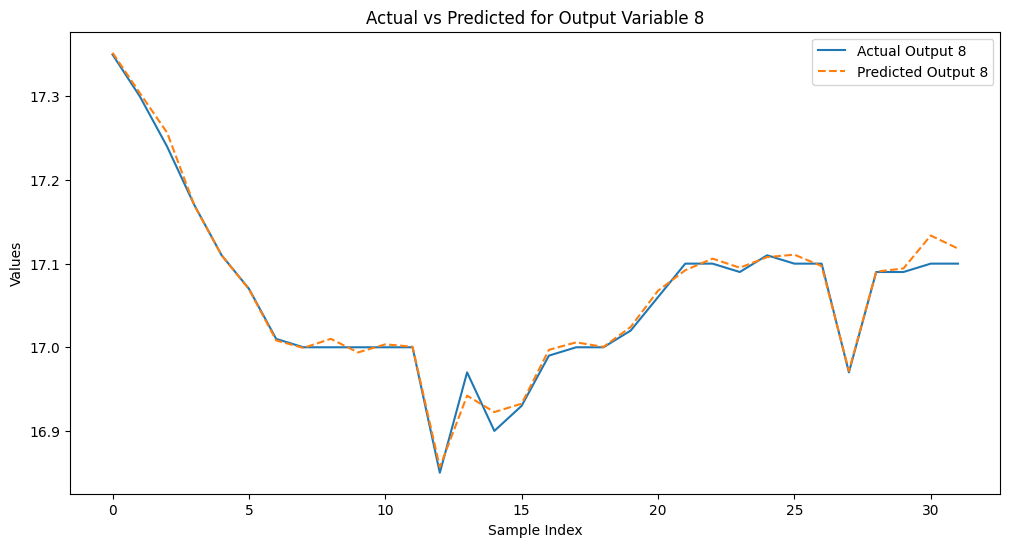

Output Variable 9: RMSE = 0.1494, MAE = 0.0787


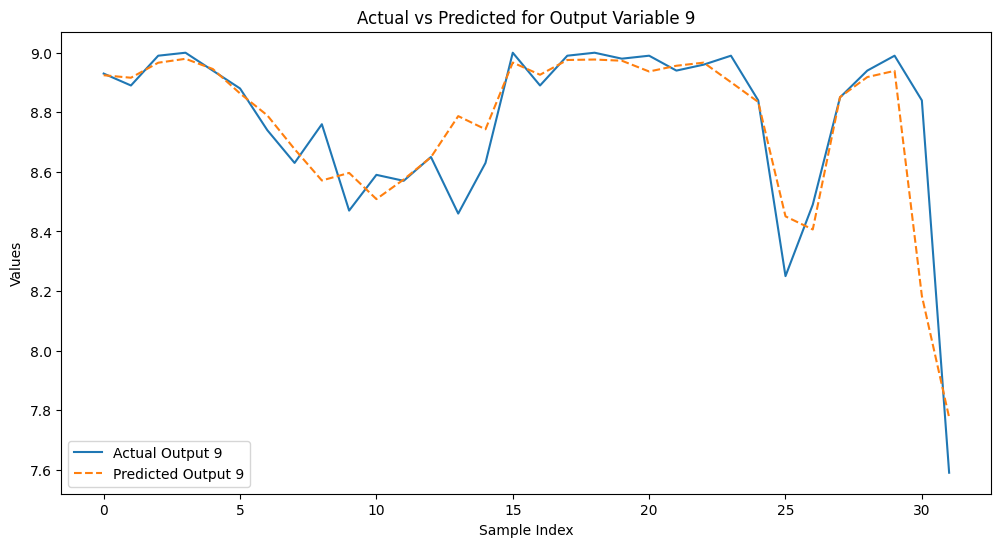

Output Variable 10: RMSE = 0.0497, MAE = 0.0322


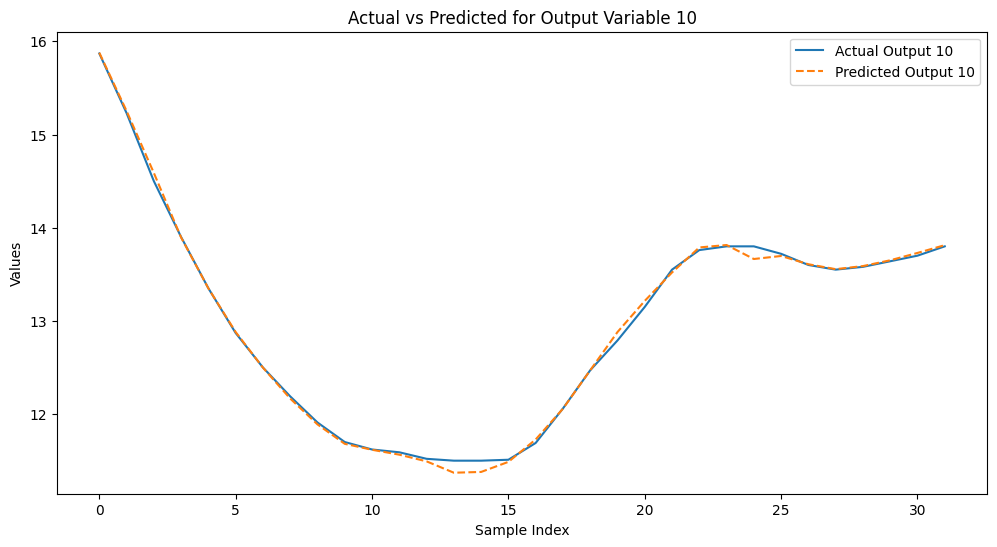

Output Variable 11: RMSE = 0.0778, MAE = 0.0537


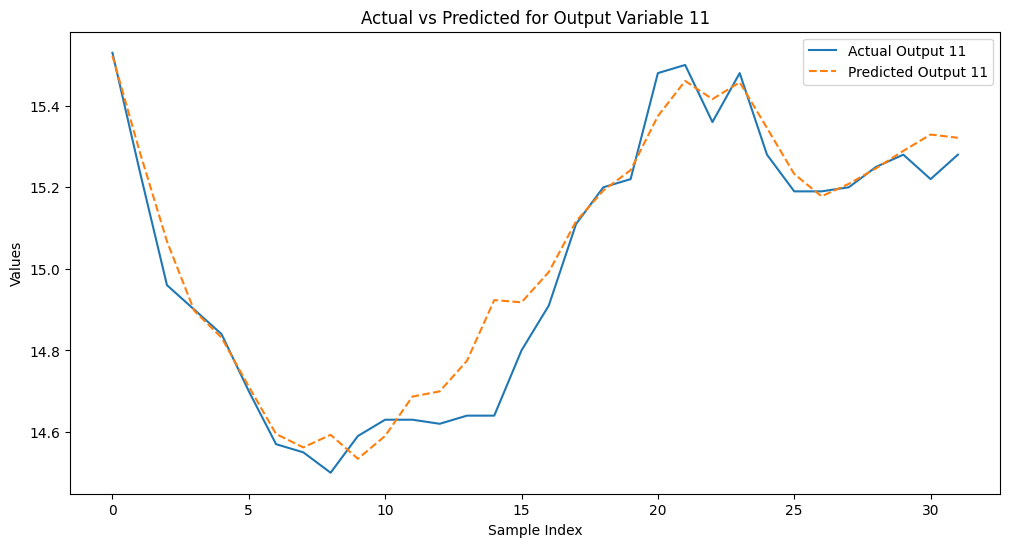

Output Variable 12: RMSE = 0.1565, MAE = 0.0870


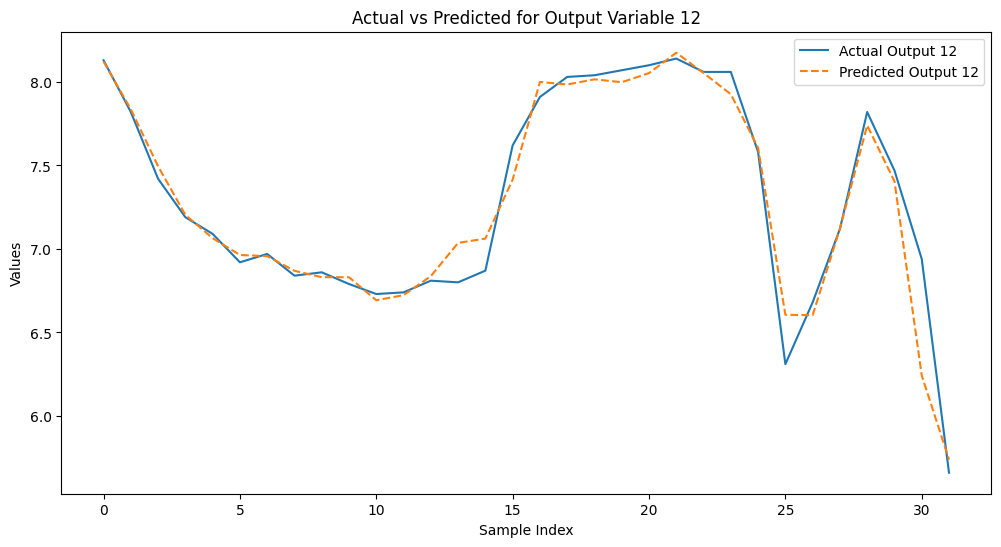

In [42]:
rmse = np.sqrt(mean_squared_error(y_test, y_preds, multioutput='raw_values'))
mae = np.mean(np.abs(y_test - y_preds), axis=0)  
for i in range(y_test.shape[1]):
    print(f"Output Variable {i+1}: RMSE = {rmse[i]:.4f}, MAE = {mae[i]:.4f}")
    plt.figure(figsize=(12, 6))
    plt.plot(y_test[:, i], label=f'Actual Output {i+1}')
    plt.plot(y_preds[:, i], label=f'Predicted Output {i+1}', linestyle='--')
    plt.xlabel('Sample Index')
    plt.ylabel('Values')
    plt.title(f'Actual vs Predicted for Output Variable {i+1}')
    plt.legend()
    plt.show()